<a href="https://colab.research.google.com/github/walbyn504/Laboratorio4-DW/blob/main/lab4_IC2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛒 Laboratorio 4 · Análisis Exploratorio de Datos (EDA)

**Universidad Técnica Nacional** · Minería de Datos ISW-911 · III Cuatrimestre 2026

**Integrantes del grupo**

| Nombre | Apellidos |
|---|---|
| Jimena | Jara Rojas |
| Walbyn | González Sequiera |
| Fiorella | Lazo Reyes |
| Seidy | Alanis Balladares |

---

### 🎯 ¿De qué trata este cuaderno?

Revisamos, limpiamos y preparamos las ventas de la cadena de supermercados **Dunnhumby** para que un modelo
pueda **predecir el importe de cada venta** (`importe_venta`).

### 🗄️ Los datos

Usamos la tabla que sale del **Data Warehouse (DW)** de nuestro proyecto, `laboratorio4_dw.csv.xz`.
Es una sola tabla donde **cada fila es un producto dentro de una compra** (una *línea de venta*):

| Grupo | Columnas | Ejemplo |
|---|---|---|
| Identificadores | `sale_detail_id`, `basket_id`, `store_id` | compra 27601281299 en la tienda 436 |
| Fecha | `calendar_date` | 2004-02-20 |
| Producto | `department`, `brand`, `category` | grocery · national · cheese |
| Hogar | `household_size`, `household_in_active_campaign` | hogar de 2 personas, en campaña |
| Promoción | `has_promotion`, `display_type` | en promoción · exhibido al frente |
| Montos | `quantity`, `sales_value`, `retail_discount`, `coupon_discount`, `coupon_match_discount` | 1 unidad · $3.99 · −$0.60 |

> 💡 **¿Por qué el DW y no las tablas de origen?** Las tablas del DW ya pasaron por el **ETL** del proyecto:
> están unidas, depuradas y los valores vacíos ya se marcaron con etiquetas. Por eso es la versión más limpia.

El archivo se lee directo desde nuestro repositorio público: https://github.com/walbyn504/Laboratorio4-DW

### 📖 ¿Cómo leer este cuaderno?

Cada sección explica **qué hacemos** y **por qué**. Después de cada resultado hay un bloque de
**Hallazgos** con lo que encontramos. Ejecuta las celdas en orden (o *Entorno de ejecución → Ejecutar todo*).

**Mini glosario**

| Término | Significado |
|---|---|
| **Línea de venta** | Un producto dentro de una compra. Una compra (canasta) tiene varias líneas. |
| **Nulo / faltante** | Un dato que no se registró. |
| **Atípico (outlier)** | Un valor muy alejado del resto. |
| **Imputar** | Rellenar un dato faltante o corregir uno erróneo con un valor razonable. |
| **ETL** | El proceso del proyecto que *extrae, transforma y carga* los datos al DW. |

### 🗂️ Contenido

1. 📥 Carga del conjunto de datos desde GitHub
2. 🔎 Características principales (funciones básicas)
3. 🔤 Nombres de columnas en español
4. ❓ Valores nulos
5. 📦 Valores atípicos
6. 🛠️ Funciones de imputación
7. 🔄 Conversión de tipos de datos
8. 🔢 Variables categóricas a numéricas
9. 📏 Estandarización
10. 🔗 Correlación
11. 🎯 Variable dependiente y modelo candidato
12. 💾 Guardado de `data_process.csv`

---
## 📥 1. Carga del conjunto de datos desde GitHub

**¿Qué hacemos?** Importamos las librerías y leemos el archivo directamente desde GitHub.

* **pandas** maneja la tabla, **numpy** ayuda con cálculos y **matplotlib** dibuja los gráficos.
* El archivo pesa 349 MB sin comprimir y GitHub no acepta archivos de más de 100 MB.
  Por eso está comprimido en formato **`xz`** (24 MB). pandas lo descomprime solo al leerlo.
* Se usa el enlace **raw** de GitHub, que entrega el archivo tal cual (no la página web).

**¿Qué mirar en el resultado?** La cantidad de filas y columnas y las primeras 5 filas de la tabla.

In [ ]:
# Librerías: pandas (tablas), numpy (cálculos), matplotlib (gráficos)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)   # mostrar todas las columnas, sin "..."

url = (
    "https://raw.githubusercontent.com/walbyn504/"
    "Laboratorio4-DW/main/Datos/origen_dw/laboratorio4_dw.csv.xz"
)

# Lectura del archivo comprimido directo desde el repositorio público
ventas = pd.read_csv(url, compression="xz")

print("Filas:", ventas.shape[0])
print("Columnas:", ventas.shape[1])
display(ventas.head())

Filas: 2595732
Columnas: 16


,sale_detail_id,basket_id,store_id,calendar_date,department,brand,category,household_size,has_promotion,display_type,household_in_active_campaign,quantity,sales_value,retail_discount,coupon_discount,coupon_match_discount
0,1,27601281299,436,2004-02-20,grocery,national,sald drsng/sndwch sprd,2,Undetermined,No causal data,Not in campaign,1,3.99,0.00,0.0,0.0
1,2,27601281299,436,2004-02-20,grocery,national,cheese,2,Undetermined,No causal data,Not in campaign,1,2.99,0.00,0.0,0.0
2,3,27601281299,436,2004-02-20,grocery,private,eggs,2,Undetermined,No causal data,Not in campaign,1,1.09,-0.30,0.0,0.0
3,4,27601281299,436,2004-02-20,deli,national,deli meats,2,Undetermined,No causal data,Not in campaign,1,3.71,-0.62,0.0,0.0
4,5,27601281299,436,2004-02-20,grocery,private,ice cream/milk/sherbts,2,Undetermined,No causal data,Not in campaign,1,2.79,-1.20,0.0,0.0


---
## 🔎 2. Características principales del conjunto de datos

**¿Qué hacemos?** Antes de cambiar nada, "conocemos" los datos con las funciones básicas de pandas:

| Función | ¿Qué responde? |
|---|---|
| `info()` | ¿Cuántas filas y columnas hay, de qué tipo es cada una y cuánta memoria usa? |
| `nunique()` | ¿Cuántos valores distintos tiene cada columna? |
| `head()`, `tail()`, `sample()` | ¿Cómo se ven las primeras, las últimas y algunas filas al azar? |
| `describe()` | ¿Cuál es el mínimo, el promedio, el máximo...? |
| `duplicated()` | ¿Hay filas repetidas? |
| `value_counts()` | ¿Cuántas veces aparece cada categoría? |

### `info()`: la ficha técnica de la tabla

Muestra cada columna con su **tipo de dato**: `int64` = número entero, `float64` = número con decimales,
`object` = texto. Al final aparece la memoria que ocupa la tabla.

In [ ]:
# Ficha técnica: columnas, tipos de dato, valores no nulos y memoria
ventas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 16 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0   sale_detail_id                int64  
 1   basket_id                     int64  
 2   store_id                      int64  
 3   calendar_date                 object 
 4   department                    object 
 5   brand                         object 
 6   category                      object 
 7   household_size                object 
 8   has_promotion                 object 
 9   display_type                  object 
 10  household_in_active_campaign  object 
 11  quantity                      int64  
 12  sales_value                   float64
 13  retail_discount               float64
 14  coupon_discount               float64
 15  coupon_match_discount         float64
dtypes: float64(4), int64(4), object(8)
memory usage: 316.9+ MB


### Resumen de cada columna

Una tabla con el **tipo**, cuántos **valores distintos** tiene y un **ejemplo** (el de la primera fila).
Pocos valores distintos indican una categoría (por ejemplo, `brand` tiene 2); muchos, un identificador o un monto.

In [ ]:
# Tipo, cantidad de valores distintos y un ejemplo de cada columna
resumen_columnas = pd.DataFrame({
    "tipo": ventas.dtypes.astype(str),
    "valores_unicos": ventas.nunique(),
    "ejemplo": ventas.iloc[0],
})
display(resumen_columnas)

,tipo,valores_unicos,ejemplo
sale_detail_id,int64,2595732,1
basket_id,int64,276484,27601281299
store_id,int64,582,436
calendar_date,object,711,2004-02-20
department,object,44,grocery
brand,object,2,national
category,object,308,sald drsng/sndwch sprd
household_size,object,6,2
has_promotion,object,2,Undetermined
display_type,object,20,No causal data


### Últimas filas y una muestra al azar

`head()` ya mostró el inicio. Aquí vemos el **final** y **5 filas al azar** (`random_state=42` hace que
siempre salgan las mismas, para que el resultado se pueda repetir).

In [ ]:
# Últimas 5 filas y 5 filas al azar
display(ventas.tail())
display(ventas.sample(5, random_state=42))

,sale_detail_id,basket_id,store_id,calendar_date,department,brand,category,household_size,has_promotion,display_type,household_in_active_campaign,quantity,sales_value,retail_discount,coupon_discount,coupon_match_discount
2595727,2595728,42250641157,447,2005-12-08,drug gm,private,cookware & bakeware,No demographic profile,Undetermined,No causal data,Not in campaign,1,3.19,-0.80,0.0,0.0
2595728,2595729,42250641157,447,2005-12-08,produce,national,broccoli/cauliflower,No demographic profile,Undetermined,No causal data,Not in campaign,1,1.99,0.00,0.0,0.0
2595729,2595730,42250641157,447,2005-12-08,grocery,national,frozen bread/dough,No demographic profile,Undetermined,No causal data,Not in campaign,1,2.59,-1.00,0.0,0.0
2595730,2595731,42250641157,447,2005-12-08,grocery,national,cold cereal,No demographic profile,Undetermined,No causal data,Not in campaign,1,2.77,-3.02,-1.0,0.0
2595731,2595732,42250641157,447,2005-12-08,nutrition,national,dried fruit,No demographic profile,Undetermined,No causal data,Not in campaign,1,1.50,-1.49,0.0,0.0


,sale_detail_id,basket_id,store_id,calendar_date,department,brand,category,household_size,has_promotion,display_type,household_in_active_campaign,quantity,sales_value,retail_discount,coupon_discount,coupon_match_discount
2386038,2386039,31527743525,372,2004-11-01,grocery,national,margarines,5+,Undetermined,No causal data,In campaign,1,2.29,0.00,0.0,0.0
1578659,1578660,40447558047,412,2005-07-30,produce,national,popcorn,No demographic profile,Undetermined,No causal data,Not in campaign,2,3.00,-2.98,0.0,0.0
1837340,1837341,33095036416,338,2005-02-16,grocery,national,water - carbonated/flvrd drink,3,Undetermined,No causal data,In campaign,1,0.99,0.00,0.0,0.0
260939,260940,32445820269,372,2005-01-03,grocery,national,bag snacks,2,Undetermined,No causal data,Not in campaign,0,0.00,0.00,0.0,0.0
2424105,2424106,32305493280,439,2004-12-28,meat-pckgd,national,hot dogs,1,Promotion,Store rear,In campaign,1,1.00,-1.19,0.0,0.0


### Estadísticas de las columnas numéricas

| Fila | Significado |
|---|---|
| **count** | Cuántos valores hay |
| **mean** | Promedio |
| **std** | Desviación estándar: qué tan dispersos están los valores |
| **min / max** | Valor más pequeño y más grande |
| **25% / 50% / 75%** | Cuartiles: el 50 % es la **mediana** (el valor del medio) |

> 👀 **Qué mirar:** en `quantity` la mediana es 1 pero el máximo es enorme, y los descuentos son
> **negativos** (así se registran los descuentos en Dunnhumby). Los identificadores también salen aquí,
> pero sus estadísticas no tienen sentido porque son códigos.

In [ ]:
# Estadísticas de las variables numéricas
display(ventas.describe().round(2))

,sale_detail_id,basket_id,store_id,quantity,sales_value,retail_discount,coupon_discount,coupon_match_discount
count,2595732.00,2.595732e+06,2595732.00,2595732.00,2595732.00,2595732.00,2595732.00,2595732.00
mean,1297866.50,3.402620e+10,3142.67,100.43,3.10,-0.54,-0.02,-0.00
std,749323.43,4.711649e+09,8937.11,1153.44,4.18,1.25,0.22,0.04
min,1.00,2.698485e+10,1.00,0.00,0.00,-180.00,-55.93,-7.70
25%,648933.75,3.040805e+10,330.00,1.00,1.29,-0.69,0.00,0.00
50%,1297866.50,3.276081e+10,372.00,1.00,2.00,-0.01,0.00,0.00
75%,1946799.25,4.012685e+10,422.00,1.00,3.49,0.00,0.00,0.00
max,2595732.00,4.230536e+10,34280.00,89638.00,840.00,3.99,0.00,0.00


### Estadísticas de las columnas de texto

| Fila | Significado |
|---|---|
| **count** | Cuántas celdas tienen dato |
| **unique** | Cuántos valores distintos hay |
| **top** | El valor más frecuente |
| **freq** | Cuántas veces aparece ese valor |

In [ ]:
# Estadísticas de las variables de texto
display(ventas.describe(exclude="number"))

,calendar_date,department,brand,category,household_size,has_promotion,display_type,household_in_active_campaign
count,2595732,2595732,2595732,2595732,2595732,2595732,2595732,2595732
unique,711,44,2,308,6,2,20,2
top,2005-11-22,grocery,national,soft drinks,No demographic profile,Undetermined,No causal data,Not in campaign
freq,7493,1646076,1849560,117532,1168429,2031958,2031958,1828306


### Duplicados y rango de fechas

Revisamos que no haya **filas repetidas** ni **identificadores de línea repetidos**, y de qué fecha a qué fecha van las ventas.

In [ ]:
# ¿Hay filas o IDs repetidos? ¿Qué periodo cubren las ventas?
print("Filas completamente duplicadas:", ventas.duplicated().sum())
print("IDs de línea de venta repetidos:", ventas["sale_detail_id"].duplicated().sum())
print("Rango de fechas:", ventas["calendar_date"].min(), "a", ventas["calendar_date"].max())

Filas completamente duplicadas: 0
IDs de línea de venta repetidos: 0
Rango de fechas: 2004-01-01 a 2005-12-11


### ¿Cómo se reparten las ventas?

Tres gráficos de barras: los **10 departamentos** con más líneas de venta, el **tipo de marca** y el
**tamaño del hogar**. En rojo está *Sin perfil*: hogares de los que no se tiene información demográfica.

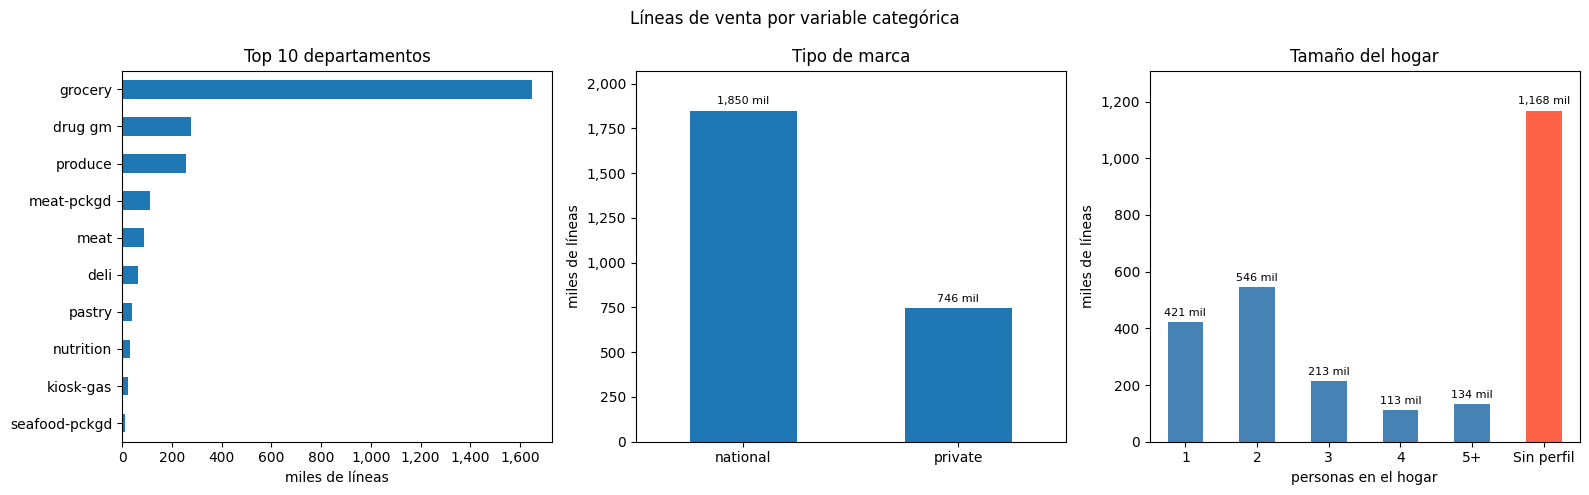

In [ ]:
# Gráficos de frecuencia de las principales variables categóricas
from matplotlib.ticker import FuncFormatter

en_miles = FuncFormatter(lambda x, _: f"{x / 1000:,.0f}")

fig, ejes = plt.subplots(1, 3, figsize=(16, 5))

# Departamentos: barras horizontales para que los nombres se lean completos
ventas["department"].value_counts().head(10).sort_values().plot.barh(ax=ejes[0])
ejes[0].set_title("Top 10 departamentos")
ejes[0].set_ylabel("")
ejes[0].xaxis.set_major_formatter(en_miles)
ejes[0].set_xlabel("miles de líneas")

# Tipo de marca
ventas["brand"].value_counts().plot.bar(ax=ejes[1], rot=0)
ejes[1].set_title("Tipo de marca")
ejes[1].set_xlabel("")
ejes[1].yaxis.set_major_formatter(en_miles)

# Tamaño del hogar: en orden 1..5+ y etiqueta corta para "No demographic profile"
orden_hogar = ["1", "2", "3", "4", "5+", "No demographic profile"]
hogar = (
    ventas["household_size"].value_counts()
    .reindex(orden_hogar)
    .rename({"No demographic profile": "Sin perfil"})
)
colores = ["steelblue"] * 5 + ["tomato"]
hogar.plot.bar(ax=ejes[2], rot=0, color=colores)
ejes[2].set_title("Tamaño del hogar")
ejes[2].set_xlabel("personas en el hogar")
ejes[2].yaxis.set_major_formatter(en_miles)

for eje in ejes[1:]:
    eje.set_ylabel("miles de líneas")
    eje.bar_label(eje.containers[0], labels=[f"{v / 1000:,.0f} mil" for v in eje.containers[0].datavalues],
                  padding=3, fontsize=8)
    eje.margins(y=0.12)

fig.suptitle("Líneas de venta por variable categórica")
plt.tight_layout()
plt.show()

### 📝 Hallazgos

* El conjunto tiene **2 595 732 líneas de venta** y **16 columnas**: 3 identificadores, 1 fecha,
  7 variables categóricas de texto y 5 numéricas.
* **No hay filas duplicadas** ni IDs de línea repetidos.
* El departamento **`grocery`** (abarrotes) concentra la mayoría de las ventas, y casi **3 de cada 4** líneas son
  de **marca nacional**.
* En `household_size` aparece la etiqueta ***No demographic profile***. No es un tamaño de hogar: es la marca
  que el ETL del DW puso cuando faltaba el dato. Se analiza en la sección 4.

---
## 🔤 3. Nombres de columnas en español

**¿Qué hacemos?** Cambiamos los nombres de las columnas del inglés al español con `rename()`, usando un
diccionario `{nombre en inglés: nombre en español}`.

**¿Por qué?** Lo pide el laboratorio y hace el análisis más fácil de leer. Los nombres van en minúsculas,
sin tildes ni espacios (por ejemplo, `tamano_hogar`), para evitar errores al escribirlos en el código.

In [ ]:
# Diccionario: nombre original (inglés) -> nombre nuevo (español)
nombres_en_espanol = {
    "sale_detail_id": "id_linea_venta",
    "basket_id": "id_compra",
    "store_id": "id_tienda",
    "calendar_date": "fecha_venta",
    "department": "departamento",
    "brand": "tipo_marca",
    "category": "categoria",
    "household_size": "tamano_hogar",
    "has_promotion": "estado_promocion",
    "display_type": "tipo_exhibicion",
    "household_in_active_campaign": "hogar_en_campana_activa",
    "quantity": "cantidad",
    "sales_value": "importe_venta",
    "retail_discount": "descuento_tienda",
    "coupon_discount": "descuento_cupon",
    "coupon_match_discount": "igualacion_descuento_cupon",
}

ventas = ventas.rename(columns=nombres_en_espanol)
print(list(ventas.columns))
display(ventas.head())

['id_linea_venta', 'id_compra', 'id_tienda', 'fecha_venta', 'departamento', 'tipo_marca', 'categoria', 'tamano_hogar', 'estado_promocion', 'tipo_exhibicion', 'hogar_en_campana_activa', 'cantidad', 'importe_venta', 'descuento_tienda', 'descuento_cupon', 'igualacion_descuento_cupon']


,id_linea_venta,id_compra,id_tienda,fecha_venta,departamento,tipo_marca,categoria,tamano_hogar,estado_promocion,tipo_exhibicion,hogar_en_campana_activa,cantidad,importe_venta,descuento_tienda,descuento_cupon,igualacion_descuento_cupon
0,1,27601281299,436,2004-02-20,grocery,national,sald drsng/sndwch sprd,2,Undetermined,No causal data,Not in campaign,1,3.99,0.00,0.0,0.0
1,2,27601281299,436,2004-02-20,grocery,national,cheese,2,Undetermined,No causal data,Not in campaign,1,2.99,0.00,0.0,0.0
2,3,27601281299,436,2004-02-20,grocery,private,eggs,2,Undetermined,No causal data,Not in campaign,1,1.09,-0.30,0.0,0.0
3,4,27601281299,436,2004-02-20,deli,national,deli meats,2,Undetermined,No causal data,Not in campaign,1,3.71,-0.62,0.0,0.0
4,5,27601281299,436,2004-02-20,grocery,private,ice cream/milk/sherbts,2,Undetermined,No causal data,Not in campaign,1,2.79,-1.20,0.0,0.0


---
## ❓ 4. Valores nulos

**¿Qué es un nulo?** Un dato que no se registró. En pandas aparece como `NaN`.

**Lo importante en nuestros datos:** en el DW, los valores que venían vacíos en el origen **ya se trataron
en el ETL**. Nuestro equipo los reemplazó por estas **etiquetas**:

| Columna | Etiqueta del ETL | Significa |
|---|---|---|
| `tamano_hogar` | *No demographic profile* | El hogar no tiene perfil demográfico |
| `estado_promocion` | *Undetermined* | No se sabe si el producto estaba en promoción |
| `tipo_exhibicion` | *No causal data* | No hay datos de exhibición en la tienda |

Por eso, en esta sección **no se vuelven a convertir en `NaN`**. Hacemos dos revisiones:

1. Comprobar que el archivo no tiene **nulos explícitos** (`NaN`).
2. Contar cuántas filas tienen cada **etiqueta de faltante**, es decir, cuántos datos venían vacíos en el origen.

### Revisión 1: nulos explícitos (`NaN`)

`isna().sum()` cuenta, por columna, cuántas celdas están vacías. Si todo da 0, el archivo no tiene `NaN`.

In [ ]:
# Cantidad de NaN por columna
nulos_explicitos = ventas.isna().sum()
print("Total de nulos explícitos (NaN):", nulos_explicitos.sum())
display(nulos_explicitos.to_frame("nulos_NaN"))

Total de nulos explícitos (NaN): 0


,nulos_NaN
id_linea_venta,0
id_compra,0
id_tienda,0
fecha_venta,0
departamento,0
tipo_marca,0
categoria,0
tamano_hogar,0
estado_promocion,0
tipo_exhibicion,0


### Revisión 2: etiquetas de faltante del ETL

Contamos cuántas filas tienen cada etiqueta y qué porcentaje del total representan.
También revisamos si *Undetermined* y *No causal data* aparecen **en las mismas filas**.

In [ ]:
# Etiquetas que el ETL usó para marcar datos faltantes en el origen
etiquetas_faltante_dw = {
    "tamano_hogar": ["No demographic profile"],
    "estado_promocion": ["Undetermined"],
    "tipo_exhibicion": ["No causal data"],
}

con_etiqueta = pd.Series(0, index=ventas.columns)
for columna, etiquetas in etiquetas_faltante_dw.items():
    con_etiqueta[columna] = ventas[columna].isin(etiquetas).sum()

tabla_nulos = pd.DataFrame({
    "nulos_NaN": nulos_explicitos,
    "etiqueta_faltante_ETL": con_etiqueta,
})
tabla_nulos["porcentaje"] = (100 * tabla_nulos.sum(axis=1) / len(ventas)).round(2)
display(tabla_nulos.sort_values("porcentaje", ascending=False))

# ¿Las etiquetas de promoción y exhibición aparecen en las mismas filas?
mismas_filas = (
    ventas["estado_promocion"].eq("Undetermined")
    == ventas["tipo_exhibicion"].eq("No causal data")
).all()
print("Undetermined y No causal data aparecen en las mismas filas:", mismas_filas)

### Evidencia gráfica: porcentaje de faltantes por columna

Cada barra es una columna. La parte roja es el porcentaje de filas con etiqueta de faltante.
Las columnas sin barra tienen todos sus datos.

In [ ]:
# Gráfico de barras: % de filas con dato faltante en cada columna
porcentajes = (100 * tabla_nulos[["nulos_NaN", "etiqueta_faltante_ETL"]] / len(ventas))
porcentajes = porcentajes.sort_values("etiqueta_faltante_ETL")

ax = porcentajes.plot.barh(stacked=True, figsize=(9, 6), color=["steelblue", "tomato"])
ax.set_title("Porcentaje de valores faltantes en el origen por columna")
ax.set_xlabel("% de filas")
ax.set_xlim(0, 100)
ax.legend(["NaN", "Etiqueta de faltante (ETL)"])
for barra, valor in zip(ax.containers[1], porcentajes.sum(axis=1)):
    if valor > 0:
        ax.text(valor + 1, barra.get_y() + barra.get_height() / 2,
                f"{valor:.1f} %", va="center")
plt.tight_layout()
plt.show()

### ¿Qué datos faltan juntos?

Este gráfico agrupa las líneas de venta según **qué datos les faltan a la vez**:

* 🟩 **Datos completos**: la venta tiene toda la información.
* 🟥 **Falta: ...**: dice qué datos faltan en esas ventas.

Así vemos si los faltantes van juntos o separados.

In [ ]:
# Agrupa las ventas según la combinación de datos que les faltan
nombres_cortos = {
    "tamano_hogar": "tamaño del hogar",
    "estado_promocion": "promoción",
    "tipo_exhibicion": "exhibición",
}
faltantes = pd.DataFrame({
    columna: ventas[columna].isin(etiquetas_faltante_dw[columna]) for columna in nombres_cortos
})


def describir_patron(fila):
    faltan = [nombres_cortos[c] for c, falta in fila.items() if falta]
    return "Datos completos" if not faltan else "Falta: " + " + ".join(faltan)


patrones = faltantes.value_counts()
patrones.index = [describir_patron(pd.Series(p, index=faltantes.columns)) for p in patrones.index]
patrones = patrones.sort_values()

ax = patrones.plot.barh(figsize=(10, 4), color=["tomato" if "Falta" in i else "seagreen"
                                                for i in patrones.index])
ax.set_title("¿Qué datos faltan juntos en cada línea de venta?")
ax.set_xlabel("miles de líneas")
ax.xaxis.set_major_formatter(lambda x, _: f"{x / 1000:,.0f}")
ax.bar_label(ax.containers[0], padding=4,
             labels=[f"{v:,.0f}  ({100 * v / len(ventas):.1f} %)" for v in patrones])
ax.margins(x=0.25)
plt.tight_layout()
plt.show()

### 📝 Hallazgos

* El archivo **no tiene `NaN`**, porque los nulos ya se trataron en el ETL del DW: se reemplazaron por etiquetas.
* `tamano_hogar` no tiene perfil demográfico en el **45 %** de las líneas (**1 168 429**).
* `estado_promocion` y `tipo_exhibicion` no tienen dato en el **78 %** (**2 031 958**) y faltan **en las mismas filas**.
  Esto indica que el faltante **no es aleatorio**: son ventas para las que el DW no tiene información causal
  (promoción y exhibición) de esa tienda y semana.
* Como la imputación ya se hizo en el ETL, las etiquetas **se conservan como categorías válidas** (sección 6).

---
## 📦 5. Valores atípicos

**¿Qué es un atípico?** Un valor muy alejado del resto, por ejemplo, alguien que compra 90 000 unidades
cuando casi todos compran 1.

**¿Cómo los detectamos?** Con la regla del **rango intercuartílico (IQR)**:

1. **Q1** es el valor que deja por debajo al 25 % de los datos y **Q3** al 75 %.
2. **IQR = Q3 − Q1** (el ancho de la "mitad central" de los datos).
3. Es atípico todo lo que esté **por debajo de Q1 − 1.5·IQR** o **por encima de Q3 + 1.5·IQR**.

Además revisamos **registros inconsistentes**: valores que no tienen sentido para el negocio, como una venta con cantidad 0.

In [ ]:
# Límites IQR y cantidad de atípicos en cada columna numérica
columnas_numericas = [
    "cantidad",
    "importe_venta",
    "descuento_tienda",
    "descuento_cupon",
    "igualacion_descuento_cupon",
]


def resumen_atipicos_iqr(tabla, columnas):
    """Devuelve una tabla con los límites IQR y la cantidad de atípicos por columna."""
    filas = []
    for columna in columnas:
        valores = tabla[columna].dropna()
        q1, q3 = valores.quantile([0.25, 0.75])
        iqr = q3 - q1
        inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        atipicos = ((valores < inferior) | (valores > superior)).sum()
        filas.append({
            "columna": columna, "Q1": q1, "Q3": q3, "IQR": iqr,
            "limite_inferior": inferior, "limite_superior": superior,
            "atipicos": atipicos,
            "porcentaje": round(100 * atipicos / len(valores), 2),
        })
    return pd.DataFrame(filas).set_index("columna")


display(resumen_atipicos_iqr(ventas, columnas_numericas).round(2))

,Q1,Q3,IQR,limite_inferior,limite_superior,atipicos,porcentaje
columna,,,,,,,
cantidad,1.00,1.00,0.00,1.00,1.00,544765,20.99
importe_venta,1.29,3.49,2.20,-2.01,6.79,190644,7.34
descuento_tienda,-0.69,0.00,0.69,-1.72,1.03,206313,7.95
descuento_cupon,0.00,0.00,0.00,0.00,0.00,36422,1.40
igualacion_descuento_cupon,0.00,0.00,0.00,0.00,0.00,17449,0.67


### Evidencia gráfica: diagramas de caja

**¿Cómo se lee?** La caja va de Q1 a Q3 y la línea del medio es la mediana. Los **puntos rojos** son los atípicos.
El eje usa escala *symlog* para poder ver a la vez valores pequeños y enormes (y también negativos).

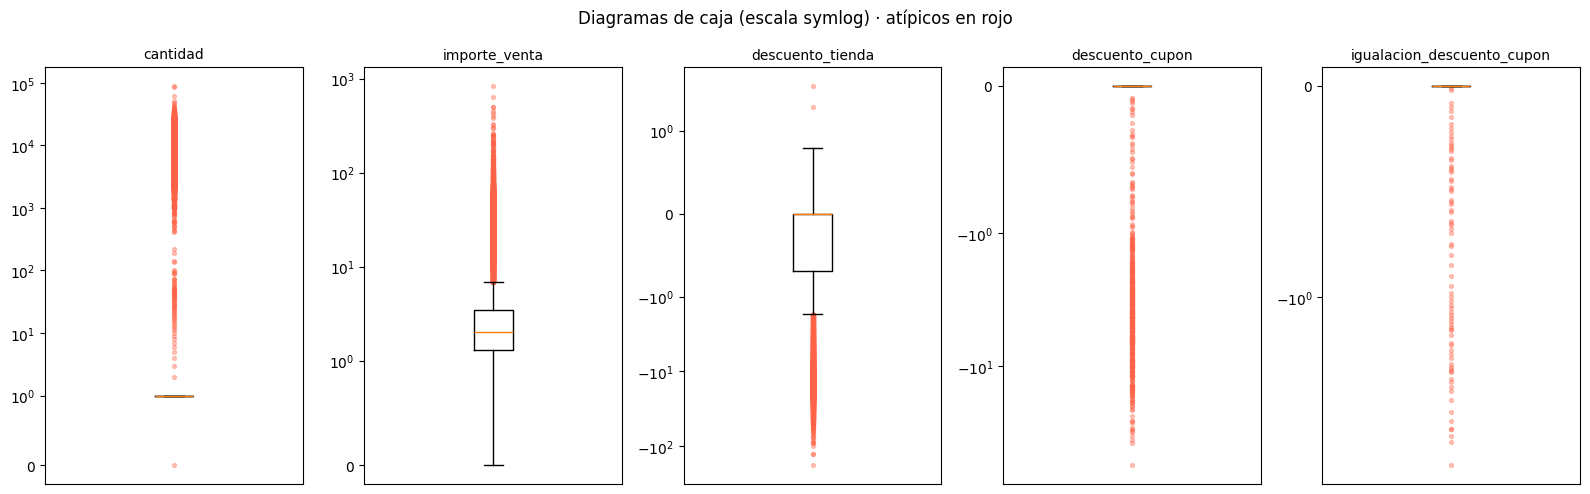

In [ ]:
# Un diagrama de caja por columna, con los atípicos en rojo
fig, ejes = plt.subplots(1, len(columnas_numericas), figsize=(16, 5))

for columna, eje in zip(columnas_numericas, ejes):
    valores = ventas[columna].dropna()
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    extremos = valores[(valores < q1 - 1.5 * iqr) | (valores > q3 + 1.5 * iqr)]

    eje.boxplot(valores, showfliers=False)
    eje.scatter([1] * extremos.nunique(), extremos.unique(),
                s=8, alpha=0.35, color="tomato")
    eje.set_yscale("symlog", linthresh=1)
    eje.set_title(columna, fontsize=10)
    eje.set_xticks([])

fig.suptitle("Diagramas de caja (escala symlog) · atípicos en rojo")
plt.tight_layout()
plt.show()

### Las 10 cantidades más grandes

¿Qué productos tienen las cantidades extremas? Esto ayuda a decidir si son errores o datos reales.

In [ ]:
# Las 10 líneas con mayor cantidad
columnas_revision = ["id_linea_venta", "departamento", "categoria", "cantidad", "importe_venta"]
display(ventas.nlargest(10, "cantidad")[columnas_revision])

,id_linea_venta,departamento,categoria,cantidad,importe_venta
615256,615257,kiosk-gas,coupon/misc items,89638,250.00
2488029,2488030,misc sales tran,coupon/misc items,85055,210.00
614422,614423,kiosk-gas,coupon/misc items,61335,150.21
154474,154475,kiosk-gas,coupon/misc items,51912,110.00
184389,184390,kiosk-gas,coupon/misc items,48073,121.10
2187447,2187448,kiosk-gas,coupon/misc items,45475,100.00
156034,156035,kiosk-gas,coupon/misc items,41833,115.00
154688,154689,kiosk-gas,coupon/misc items,41686,100.00
1429860,1429861,misc sales tran,coupon/misc items,41485,85.00
111741,111742,kiosk-gas,coupon/misc items,39365,72.00


### Los 10 importes más grandes

In [ ]:
# Las 10 líneas con mayor importe
columnas_revision = ["id_linea_venta", "departamento", "categoria", "cantidad", "importe_venta"]
display(ventas.nlargest(10, "importe_venta")[columnas_revision])

,id_linea_venta,departamento,categoria,cantidad,importe_venta
1640996,1640997,misc sales tran,coupon/misc items,3,840.00
341169,341170,drug gm,tickets,5,631.80
132888,132889,misc. trans.,no commodity description,2,505.00
375193,375194,drug gm,spring/summer seasonal,1,499.99
132813,132814,misc. trans.,no commodity description,1,455.00
2122429,2122430,misc. trans.,no commodity description,1,430.00
60911,60912,misc. trans.,no commodity description,1,400.00
2479220,2479221,misc. trans.,no commodity description,1,380.00
1136004,1136005,drug gm,spring/summer seasonal,1,329.99
2079259,2079260,floral,gift & fruit baskets,25,324.75


### ¿En qué departamentos están las cantidades extremas?

Comparamos la **mediana** (lo normal) con el **máximo** de cada departamento.

,median,max
departamento,,
kiosk-gas,10005.0,89638
misc sales tran,2.0,85055
produce,1.0,144
drug gm,1.0,90
grocery,1.0,60
meat,1.0,40
pastry,1.0,32
nutrition,1.0,30


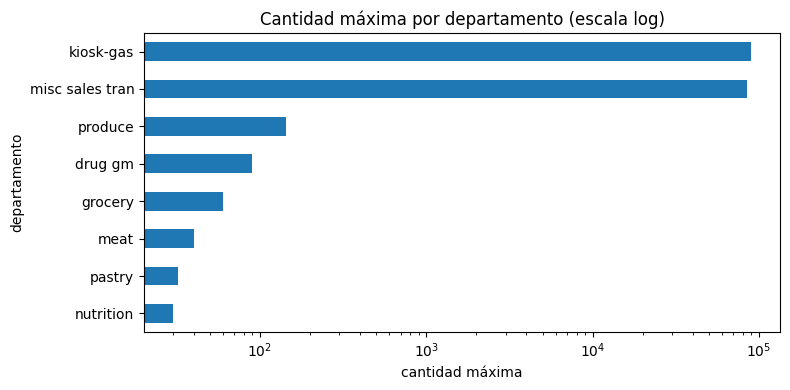

In [ ]:
# ¿En qué departamentos están las cantidades extremas?
cantidad_por_depto = (
    ventas.groupby("departamento")["cantidad"]
    .agg(["median", "max"])
    .sort_values("max", ascending=False)
    .head(8)
)
display(cantidad_por_depto)

ax = cantidad_por_depto["max"].sort_values().plot.barh(figsize=(8, 4), logx=True)
ax.set_title("Cantidad máxima por departamento (escala log)")
ax.set_xlabel("cantidad máxima")
plt.tight_layout()
plt.show()

### Registros revisados por lógica del negocio

* 🟥 **Cantidad 0**: una venta no puede tener 0 unidades, así que es un **error**.
* 🟩 **Importe 0**: el producto se llevó con **descuento total**; es un dato **válido**.

In [ ]:
# Cantidad 0 (error) vs importe 0 (válido)
revision = pd.Series({
    "Cantidad 0 (error)": (ventas["cantidad"] == 0).sum(),
    "Importe 0 (descuento total, válido)": (ventas["importe_venta"] == 0).sum(),
})
display(revision.to_frame("lineas"))

ax = revision.plot.barh(figsize=(9, 2.8), color=["tomato", "seagreen"])
ax.set_title("Registros revisados por lógica del negocio")
ax.set_xlabel("líneas de venta")
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=4)
ax.margins(x=0.2)
plt.tight_layout()
plt.show()

### 📝 Hallazgos

* En `cantidad`, **Q1 = Q3 = 1**, así que el IQR es 0 y **cualquier valor distinto de 1 sale como atípico**.
  Por eso el IQR no sirve en esta columna y se usan **percentiles** (sección 6).
* Las cantidades extremas (hasta ~90 000) vienen de **`kiosk-gas`** y **`misc sales tran`**: la unidad no es
  comparable con la del resto de productos (por ejemplo, combustible).
* En los descuentos, la mayoría de valores es 0, así que el IQR también marca como atípico cualquier descuento.
  Esos valores **son reales y se conservan**.
* Hay **14 466** líneas con **cantidad 0**: una venta no puede tener 0 unidades. Se tratarán como faltantes.
* Hay unas **18 850** líneas con **importe 0**: productos con descuento total. Son válidas y se conservan.

---
## 🛠️ 6. Funciones de imputación

**¿Qué es imputar?** Rellenar un dato faltante o corregir uno erróneo con un valor razonable,
**sin borrar filas**.

**¿Qué hacemos?** Creamos 3 funciones, una por cada tipo de problema que encontramos en las secciones 4 y 5:

| Función | ¿Qué hace? |
|---|---|
| `traducir_etiqueta_faltante` | Conserva la imputación del ETL: traduce la etiqueta al español y crea una columna 0/1 que marca esas filas |
| `imputar_mediana_por_grupo` | Rellena un valor faltante con la **mediana de su grupo** (por ejemplo, de su categoría de producto) |
| `recortar_atipicos` | Lleva los valores extremos a un límite (percentil 1 y 99) en lugar de borrarlos |

**Decisiones y justificación:**

| Hallazgo | Tratamiento | Justificación |
|---|---|---|
| `tamano_hogar` con *No demographic profile* (45 %) | **Ya imputado en el ETL** con una constante. Se conserva; solo se traduce a **"Desconocido"** y se agrega el indicador `sin_perfil_demografico` | Imputar la moda (hogar de 2) inventaría el tamaño de casi la mitad de los hogares. La constante es la decisión correcta y ya estaba aplicada en el DW. |
| `estado_promocion` y `tipo_exhibicion` con *Undetermined* / *No causal data* (78 %) | **Ya imputado en el ETL** con una constante. Se conserva; solo se traduce a **"Sin dato"** y se agrega el indicador `sin_dato_causal` | El faltante no es aleatorio (falta toda la información causal). El indicador permite al modelo distinguir esas filas. |
| `cantidad = 0` (14 466) | Convertir a `NaN` e imputar con la **mediana de su categoría** | Una venta no puede tener cantidad 0. La mediana por categoría respeta las unidades de cada producto y no es sensible a extremos. |
| `cantidad` extrema | **Recorte (winsorización) a los percentiles 1 y 99** | El IQR es 0 en esta columna. Recortar limita el efecto de las unidades no comparables (combustible) sin borrar filas. |
| `importe_venta` y descuentos extremos | **Se conservan** | Son valores reales. `importe_venta` es la variable objetivo y recortarla sesgaría el modelo. |

In [ ]:
def traducir_etiqueta_faltante(tabla, columna, etiqueta, nuevo_valor, indicador=None):
    """Conserva la imputación por constante que se hizo en el ETL del DW.

    Cambia la etiqueta en inglés por `nuevo_valor` (en español) y, si se da `indicador`,
    crea una columna 0/1 que marca las filas que venían vacías en el origen.
    Devuelve la cantidad de filas con esa etiqueta.
    """
    con_etiqueta = tabla[columna] == etiqueta
    if indicador:
        tabla[indicador] = con_etiqueta.astype("int8")
    tabla[columna] = tabla[columna].replace(etiqueta, nuevo_valor)
    return int(con_etiqueta.sum())


def imputar_mediana_por_grupo(tabla, columna, grupo):
    """Imputa los NaN de una columna numérica con la mediana de su grupo.

    Si un grupo no tiene ningún valor, se usa la mediana global.
    """
    faltantes = tabla[columna].isna()
    if not faltantes.any():
        return 0

    medianas = tabla.groupby(grupo, observed=True)[columna].transform("median")
    tabla[columna] = tabla[columna].fillna(medianas).fillna(tabla[columna].median())
    return int(faltantes.sum())


def recortar_atipicos(tabla, columna, inferior=0.01, superior=0.99):
    """Winsoriza una columna: lleva los valores fuera de los percentiles a esos límites."""
    limite_inf, limite_sup = tabla[columna].quantile([inferior, superior])
    fuera = ((tabla[columna] < limite_inf) | (tabla[columna] > limite_sup)).sum()
    tabla[columna] = tabla[columna].clip(limite_inf, limite_sup)
    return int(fuera), limite_inf, limite_sup

### Aplicamos las funciones

1. **Imputación del ETL:** se conserva, se traduce a "Desconocido" o "Sin dato" y se crean los indicadores
   `sin_perfil_demografico` y `sin_dato_causal` (1 = venía vacío en el origen).
2. **Cantidad 0:** se convierte en `NaN` y se rellena con la mediana de su categoría.
3. **Cantidad extrema:** se recorta al rango de los percentiles 1 y 99.

**¿Qué mirar en el resultado?** Cuántas filas se trataron en cada paso y que al final queden **0 nulos**.

In [ ]:
tratados = {}

# 1) Imputación hecha en el ETL: se conserva, se traduce la etiqueta y se agrega un indicador
tratados["tamano_hogar (ETL)"] = traducir_etiqueta_faltante(
    ventas, "tamano_hogar", "No demographic profile", "Desconocido",
    indicador="sin_perfil_demografico")
tratados["estado_promocion (ETL)"] = traducir_etiqueta_faltante(
    ventas, "estado_promocion", "Undetermined", "Sin dato", indicador="sin_dato_causal")
tratados["tipo_exhibicion (ETL)"] = traducir_etiqueta_faltante(
    ventas, "tipo_exhibicion", "No causal data", "Sin dato")

# 2) Cantidad 0 -> NaN -> mediana de su categoría
ventas["cantidad"] = ventas["cantidad"].mask(ventas["cantidad"] == 0)
tratados["cantidad = 0 (mediana)"] = imputar_mediana_por_grupo(ventas, "cantidad", "categoria")

# 3) Atípicos extremos de cantidad -> recorte P1-P99
n, li, ls = recortar_atipicos(ventas, "cantidad")
tratados["cantidad extrema (recorte)"] = n
print(f"Rango de cantidad después del recorte: [{li:.0f}, {ls:.0f}]")

display(pd.Series(tratados).to_frame("filas_tratadas"))
print("Nulos restantes en el conjunto:", ventas.isna().sum().sum())

### Evidencia gráfica: filas tratadas

* 🟦 **Azul:** imputación que **ya venía hecha del ETL** (solo se tradujo).
* 🟥 **Rojo:** tratamiento que hicimos **en este EDA**.

Abajo, el diagrama de caja de `cantidad` después de imputar y recortar: ya no hay valores extremos.

In [ ]:
# Gráfico de filas tratadas y diagrama de caja final de cantidad
serie_tratados = pd.Series(tratados).sort_values()
colores = ["steelblue" if "ETL" in nombre else "tomato" for nombre in serie_tratados.index]

ax = serie_tratados.plot.barh(figsize=(10, 4), color=colores)
ax.set_title("Filas tratadas (azul = imputación ya hecha en el ETL, rojo = tratamiento de este EDA)")
ax.set_xlabel("miles de líneas")
ax.xaxis.set_major_formatter(lambda x, _: f"{x / 1000:,.0f}")
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=4)
ax.margins(x=0.2)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(ventas["cantidad"])
ax.set_title("cantidad después de imputar y recortar")
ax.set_xticks([])
plt.tight_layout()
plt.show()

---
## 🔄 7. Conversión de tipos de datos

**¿Qué hacemos?** Le damos a cada columna el tipo de dato que le corresponde:

| Columna | Antes | Después | ¿Por qué? |
|---|---|---|---|
| `fecha_venta` | texto | `datetime` (fecha) | Permite sacar el **año**, el **mes** y el **día de la semana** |
| `id_linea_venta`, `id_compra`, `id_tienda` | número | texto | Son códigos, no cantidades: no tiene sentido sumarlos ni promediarlos |
| Columnas de texto con pocos valores | texto | `category` | Ocupa **mucha menos memoria** |
| `cantidad` | decimal | entero | Después de imputar vuelve a ser un número de unidades |

**¿Qué mirar en el resultado?** La memoria antes y después (baja de unos 1 321 MB a 569 MB) y el nuevo tipo de cada columna.

In [ ]:
# Memoria antes de convertir, para comparar al final
memoria_antes = ventas.memory_usage(deep=True).sum() / 1024**2

ventas["fecha_venta"] = pd.to_datetime(ventas["fecha_venta"], format="%Y-%m-%d")
ventas["anio"] = ventas["fecha_venta"].dt.year.astype("int16")
ventas["mes"] = ventas["fecha_venta"].dt.month.astype("int8")
ventas["dia_semana"] = ventas["fecha_venta"].dt.dayofweek.astype("int8")  # 0 = lunes

for columna in ["id_linea_venta", "id_compra", "id_tienda"]:
    ventas[columna] = ventas[columna].astype("string")

columnas_categoricas = [
    "departamento", "tipo_marca", "categoria", "tamano_hogar",
    "estado_promocion", "tipo_exhibicion", "hogar_en_campana_activa",
]
for columna in columnas_categoricas:
    ventas[columna] = ventas[columna].astype("category")

ventas["cantidad"] = ventas["cantidad"].round().astype("int64")

memoria_despues = ventas.memory_usage(deep=True).sum() / 1024**2
print(f"Memoria: {memoria_antes:,.0f} MB -> {memoria_despues:,.0f} MB")
display(ventas.dtypes.to_frame("tipo"))

---
## 🔢 8. Conversión de variables categóricas a numéricas

**¿Qué hacemos?** Los modelos solo entienden números, así que convertimos el texto en números.
Usamos una técnica distinta según el tipo de variable:

* **Binaria (0/1):** la variable responde sí o no. 1 = sí, 0 = no.
* **Ordinal:** las categorías tienen un orden (hogar de 1, 2, 3... personas).
* **One-hot:** se crea una columna 0/1 por cada categoría.
* **Por etiqueta:** cada categoría recibe un número; se usa cuando hay demasiadas categorías.

| Variable | Valores | Técnica |
|---|---|---|
| `tipo_marca`, `hogar_en_campana_activa`, `estado_promocion` | 2 | Binaria 0/1 |
| `tamano_hogar` | 1, 2, 3, 4, 5+, Desconocido | Ordinal 1–5 (Desconocido = 0, ya marcado en `sin_perfil_demografico`) |
| `tipo_exhibicion` | 20 | One-hot (`get_dummies`) |
| `departamento`, `categoria` | 44 y 308 | Codificación por etiqueta (`cat.codes`): one-hot crearía más de 350 columnas para 2.6 millones de filas, y el árbol de regresión propuesto trabaja bien con códigos |

In [ ]:
# Tabla aparte con las versiones numéricas (las columnas de texto originales se conservan)
codificadas = pd.DataFrame(index=ventas.index)

# Binarias: 1 = sí, 0 = no
codificadas["es_marca_propia"] = (ventas["tipo_marca"] == "private").astype("int8")
codificadas["en_campana"] = (ventas["hogar_en_campana_activa"] == "In campaign").astype("int8")
codificadas["en_promocion"] = (ventas["estado_promocion"] == "Promotion").astype("int8")

# Ordinal: respeta el orden del tamaño del hogar (Desconocido = 0)
orden_hogar = {"1": 1, "2": 2, "3": 3, "4": 4, "5+": 5, "Desconocido": 0}
codificadas["tamano_hogar_num"] = (
    ventas["tamano_hogar"].astype(str).map(orden_hogar).astype("int8")
)

# Por etiqueta: cada departamento y categoría recibe un número
codificadas["departamento_cod"] = ventas["departamento"].cat.codes.astype("int16")
codificadas["categoria_cod"] = ventas["categoria"].cat.codes.astype("int16")

# One-hot: una columna 0/1 por cada tipo de exhibición
exhibicion = pd.get_dummies(ventas["tipo_exhibicion"], prefix="exhib", dtype="int8")
exhibicion.columns = (
    exhibicion.columns.str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)
codificadas = pd.concat([codificadas, exhibicion], axis=1)

print("Columnas numéricas creadas:", codificadas.shape[1])
display(codificadas.head())

---
## 📏 9. Estandarización

**¿Qué hacemos?** Ponemos las variables numéricas en la misma escala con el **z-score**:

> **z = (valor − promedio) / desviación estándar**

Después de esto cada variable tiene **promedio 0** y **desviación 1**. Así, una variable con valores grandes
no "pesa" más que otra con valores pequeños solo por su escala.

* Elegimos **estandarizar** en vez de normalizar (min-max, de 0 a 1) porque los descuentos y la cantidad tienen
  valores extremos: con min-max casi todos los datos quedarían apretados cerca de 0.
* **No estandarizamos `importe_venta`**, porque es lo que queremos predecir y conviene dejarlo en dólares.

**¿Qué mirar en el resultado?** Que cada columna `_z` tenga promedio 0 y desviación 1. En el gráfico, las dos
formas son iguales: estandarizar no cambia la forma, solo la escala del eje X.

In [ ]:
# Función de estandarización z-score
def estandarizar_z(tabla, columnas):
    """Devuelve las columnas estandarizadas (x - media) / desviación, con sufijo _z."""
    datos = tabla[columnas].astype("float64")
    return ((datos - datos.mean()) / datos.std(ddof=0)).add_suffix("_z")


columnas_a_estandarizar = [
    "cantidad", "descuento_tienda", "descuento_cupon", "igualacion_descuento_cupon",
]
estandarizadas = estandarizar_z(ventas, columnas_a_estandarizar)

display(pd.DataFrame({
    "media": estandarizadas.mean(),
    "desviacion_estandar": estandarizadas.std(ddof=0),
}).round(3))

# Estandarizar no cambia la forma, solo la escala del eje X (de $ a desviaciones)
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ventas["descuento_tienda"].plot.hist(bins=60, ax=ejes[0], log=True)
ejes[0].set_title("descuento_tienda (original)")
estandarizadas["descuento_tienda_z"].plot.hist(bins=60, ax=ejes[1], log=True, color="seagreen")
ejes[1].set_title("descuento_tienda_z (estandarizado)")
plt.tight_layout()
plt.show()

### Unimos todo en una sola tabla

`ventas_procesadas` junta las columnas originales ya limpias, las codificadas (sección 8) y las estandarizadas (sección 9).

In [ ]:
# Tabla final = datos limpios + columnas codificadas + columnas estandarizadas
ventas_procesadas = pd.concat([ventas, codificadas, estandarizadas], axis=1)
print("Filas y columnas:", ventas_procesadas.shape)

---
## 🔗 10. Correlación

**¿Qué es?** La correlación de **Pearson** mide qué tan relacionadas están dos variables, de **−1 a 1**:

| Valor | Significado |
|---|---|
| Cerca de **1** | Cuando una sube, la otra también sube |
| Cerca de **−1** | Cuando una sube, la otra baja |
| Cerca de **0** | No hay relación lineal |

**¿Cómo leer el mapa de calor?** Cada cuadro cruza dos variables. **Rojo** = relación positiva,
**azul** = relación negativa, **blanco** = sin relación. Lo más importante es la fila de `importe_venta`,
porque es lo que queremos predecir.

In [ ]:
# Matriz de correlación entre la variable objetivo y los predictores
columnas_correlacion = [
    "importe_venta", "cantidad", "descuento_tienda", "descuento_cupon",
    "igualacion_descuento_cupon", "es_marca_propia", "en_promocion", "sin_dato_causal",
    "en_campana", "tamano_hogar_num", "sin_perfil_demografico", "mes", "dia_semana",
]
correlacion = ventas_procesadas[columnas_correlacion].corr(method="pearson")

fig, ax = plt.subplots(figsize=(11, 9))
imagen = ax.imshow(correlacion, cmap="coolwarm", vmin=-1, vmax=1)
posiciones = range(len(columnas_correlacion))
ax.set_xticks(posiciones, columnas_correlacion, rotation=45, ha="right")
ax.set_yticks(posiciones, columnas_correlacion)
for i in posiciones:
    for j in posiciones:
        valor = correlacion.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(valor) > 0.65 else "black")
ax.set_title("Matriz de correlación de Pearson")
fig.colorbar(imagen, ax=ax, label="Correlación")
plt.tight_layout()
plt.show()

### Correlación de cada variable con `importe_venta`

Las barras **azules** son relaciones positivas y las **rojas**, negativas. Cuanto más larga la barra, más fuerte la relación.

In [ ]:
# Correlación de cada variable con importe_venta, ordenada
con_objetivo = correlacion["importe_venta"].drop("importe_venta").sort_values()
display(con_objetivo.round(3).to_frame("correlacion_con_importe_venta"))

ax = con_objetivo.plot.barh(
    figsize=(8, 5), color=np.where(con_objetivo < 0, "tomato", "steelblue")
)
ax.set_title("Correlación de cada variable con importe_venta")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

### 📝 Hallazgos

* `cantidad` es la variable con mayor relación con `importe_venta` (**r ≈ 0.48**, positiva y moderada): a más unidades, mayor importe.
* `descuento_tienda` tiene **r ≈ −0.25**. Los descuentos se registran como números negativos, así que el signo negativo significa que las líneas con mayor descuento suelen tener un importe más alto (productos más caros).
* `en_promocion` y `sin_dato_causal` tienen **r = −1**: en este conjunto, `estado_promocion` solo toma los valores *Promotion* y *Sin dato*, así que una columna es exactamente la opuesta de la otra. Para el modelo basta con usar una de las dos y evitar la multicolinealidad.
* `tamano_hogar_num` y `sin_perfil_demografico` (**r ≈ −0.78**) también son redundantes en parte, porque el código 0 del tamaño corresponde a "Desconocido".
* Las demás variables (mes, día de la semana, campaña, tipo de marca) tienen correlación lineal casi nula con el importe. Eso no descarta relaciones no lineales o por categoría, que es la razón para proponer un árbol de regresión.

---
## 🎯 11. Variable dependiente y modelo candidato

**Variable dependiente:** `importe_venta`, el monto cobrado en cada línea de venta.

**Tipo de problema:** como `importe_venta` es una variable **numérica continua**, el problema es de **regresión**
(no de clasificación).

**Modelo propuesto: árbol de regresión.**

* La correlación lineal de cada variable con el importe es débil o moderada (sección 10). Un modelo lineal
  no captaría bien relaciones que cambian según el producto. El árbol, en cambio, divide los datos por
  categoría, departamento, tipo de marca o promoción y estima el importe dentro de cada grupo.
* Trabaja bien con las variables codificadas por etiqueta (`categoria_cod`, `departamento_cod`) y no
  necesita que los datos estén estandarizados.
* Es interpretable: se pueden leer las reglas que llevan a cada predicción.

**Modelo de referencia:** una **regresión lineal múltiple** con las variables estandarizadas, para comparar
el error del árbol contra un modelo simple.

**Precaución:** los descuentos se registran en el mismo momento de la venta. Si el objetivo es predecir el
importe *antes* de la compra, habría que excluirlos para no filtrar información del resultado.

---
## 💾 12. Guardado del conjunto de datos procesado

**¿Qué hacemos?** Guardamos la tabla final en **`data_process.csv`**, con todas las actividades del EDA aplicadas:

* nombres en español,
* faltantes imputados y atípicos tratados,
* tipos de dato convertidos,
* variables codificadas y estandarizadas.

**¿Dónde queda?** En el panel de archivos de Colab (ícono de carpeta 📁 a la izquierda).
Es temporal: se borra al cerrar la sesión, así que si lo necesitas, descárgalo o guárdalo en Drive.

In [ ]:
# Guardar la tabla final y comprobar que se puede volver a leer
ventas_procesadas.to_csv("data_process.csv", index=False)

import os
print("Archivo guardado: data_process.csv")
print("Filas y columnas:", ventas_procesadas.shape)
print(f"Tamaño: {os.path.getsize('data_process.csv') / 1024**2:,.0f} MB")
display(pd.read_csv("data_process.csv", nrows=5))

# Para descargarlo desde Colab (opcional, el archivo es grande):
# from google.colab import files
# files.download("data_process.csv")

---
## ✅ Resumen del EDA

| Paso | Resultado |
|---|---|
| 📥 Carga | 2 595 732 líneas de venta y 16 columnas, leídas desde GitHub |
| 🔤 Nombres | Todas las columnas en español |
| ❓ Nulos | 0 `NaN`; las etiquetas del ETL (45 % y 78 %) se conservan como categorías con su indicador |
| 📦 Atípicos | Cantidad 0 (14 466) imputada con la mediana; cantidades extremas (25 545) recortadas a [1, 10] |
| 🔄 Tipos | Fechas, identificadores y categorías con su tipo correcto; memoria de 1 321 MB a 569 MB |
| 🔢 Codificación | Binaria, ordinal, one-hot y por etiqueta |
| 📏 Estandarización | z-score en cantidad y descuentos |
| 🔗 Correlación | `cantidad` es la variable más relacionada con el importe (r ≈ 0.48) |
| 🎯 Modelo | Regresión: árbol de regresión (referencia: regresión lineal múltiple) |
| 💾 Resultado | `data_process.csv` con 2 595 732 filas y 51 columnas, 0 nulos |